# NLP-Based Sentiment Analysis of Customer Reviews

## Project Overview

This project focuses on analysing customer reviews of Samsung mobile phones using Natural Language Processing (NLP).

The objective is to identify customer opinions and classify reviews into three sentiment categories: Positive, Negative and Neutral.

The project involves exploratory data analysis, text preprocessing, feature extraction, machine learning model development, model evaluation and deployment.

## Business Objective

To extract and analyse sentiment from customer product reviews using Natural Language Processing techniques and develop a system that can classify customer reviews based on their expressed opinions.

In [4]:
# Importing the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("NLP Sentiment Analysis Project")
print("Libraries imported successfully!")

NLP Sentiment Analysis Project
Libraries imported successfully!


In [5]:
# Load the customer review dataset

df = pd.read_excel("Dataset (2).xlsx")

print("Dataset loaded successfully!")

print("\nFirst 5 Customer Reviews:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!

First 5 Customer Reviews:


,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."



Dataset Shape:
(1440, 3)

Column Names:
['title', 'rating', 'body']


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure, characteristics and patterns within the customer review dataset.

This stage involves examining the dataset information, identifying missing values and duplicate records, analysing customer ratings and visualising the distribution of reviews.

In [6]:
# Check dataset information

print("DATASET INFORMATION")
print("=" * 40)

df.info()


# Check for missing values

print("\nMISSING VALUES")
print("=" * 40)

print(df.isnull().sum())


# Check for duplicate records

print("\nDUPLICATE RECORDS")
print("=" * 40)

print("Number of duplicate rows:", df.duplicated().sum())


# Understand rating distribution

print("\nRATING DISTRIBUTION")
print("=" * 40)

print(df["rating"].value_counts().sort_index())


# Statistical summary

print("\nSTATISTICAL SUMMARY")
print("=" * 40)

display(df.describe())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   1440 non-null   str  
 1   rating  1440 non-null   int64
 2   body    1440 non-null   str  
dtypes: int64(1), str(2)
memory usage: 508.5 KB

MISSING VALUES
title     0
rating    0
body      0
dtype: int64

DUPLICATE RECORDS
Number of duplicate rows: 0

RATING DISTRIBUTION
rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64

STATISTICAL SUMMARY


,rating
count,1440.000000
mean,3.173611
std,1.584453
min,1.000000
25%,1.000000
50%,4.000000
75%,5.000000
max,5.000000


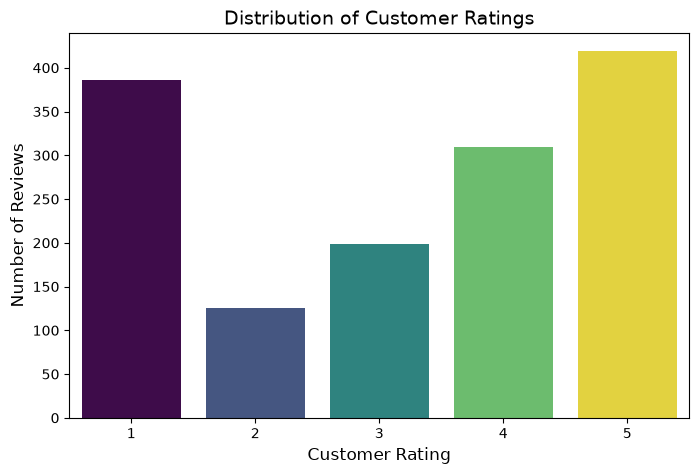

In [7]:
# Visualise the distribution of customer ratings

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating",
    hue="rating",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Customer Ratings", fontsize=14)
plt.xlabel("Customer Rating", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)

plt.show()

The graph indicates that customer opinions are divided.
- Five-star ratings are the most frequent, with 419 reviews.
- One-star ratings are the second most frequent, with 386 reviews.
- Two-star ratings have the lowest frequency, with 126 reviews.
  
Although five-star ratings are the most common, there is also a considerable number of one-star reviews. This suggests that the product has received both positive and negative feedback.

In [8]:
# Combine review title and review body

df["review"] = df["title"] + " " + df["body"]

# Display original and combined customer reviews

print("Original and Combined Customer Reviews:")

display(df[["title", "body", "review"]].head())

print("\nTotal Reviews:", len(df))

Original and Combined Customer Reviews:


,title,body,review
0,Horrible product,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...
1,Camera quality is not like 48 megapixel,Camera quality is low,Camera quality is not like 48 megapixel Camera...
2,Overall,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt..."
3,A big no from me,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...
4,Put your money somewhere else,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...



Total Reviews: 1440


In [9]:
# Import the regular expression library

import re


# Define a function to clean customer reviews

def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove website URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters, numbers and punctuation
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply text cleaning to all customer reviews

df["cleaned_review"] = df["review"].apply(clean_text)


# Display original and cleaned reviews

print("Original and Cleaned Customer Reviews:")

display(df[["review", "cleaned_review"]].head())

print("\nText cleaning completed successfully!")

Original and Cleaned Customer Reviews:


,review,cleaned_review
0,Horrible product Very disappointed with the ov...,horrible product very disappointed with the ov...
1,Camera quality is not like 48 megapixel Camera...,camera quality is not like megapixel camera qu...
2,"Overall Got the mobile on the launch date,Batt...",overall got the mobile on the launch date batt...
3,A big no from me 1. It doesn't work with 5.0GH...,a big no from me it doesn t work with ghz wifi...
4,Put your money somewhere else Not worth buying...,put your money somewhere else not worth buying...



Text cleaning completed successfully!


In [19]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [10]:
# Tokenization and Stop-Word Removal

# Import required libraries

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Download the English stopwords dataset

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

# Load English stop words

stop_words = set(stopwords.words("english"))

# Preserve important negation words

stop_words = stop_words - {"not", "no", "nor", "never"}

# Define a function for tokenization and stop-word removal

def tokenize_text(text):

    # Break the text into individual words
    tokens = word_tokenize(text)

    # Remove stop words and retain meaningful words
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return tokens

# Apply the function to all cleaned reviews

df["tokens"] = df["cleaned_review"].apply(tokenize_text)

# Display the results

print("Tokenization and Stop-Word Removal:")
display(df[["cleaned_review", "tokens"]].head())

print("\nTokenization completed successfully!")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\adish\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\adish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\adish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\adish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Tokenization and Stop-Word Removal:


,cleaned_review,tokens
0,horrible product very disappointed with the ov...,"[horrible, product, disappointed, overall, per..."
1,camera quality is not like megapixel camera qu...,"[camera, quality, not, like, megapixel, camera..."
2,overall got the mobile on the launch date batt...,"[overall, got, mobile, launch, date, battery, ..."
3,a big no from me it doesn t work with ghz wifi...,"[big, no, work, ghz, wifi, frequency, ghz, old..."
4,put your money somewhere else not worth buying...,"[put, money, somewhere, else, not, worth, buyi..."



Tokenization completed successfully!


### Tokenisation and Stop-word Removal

Tokenisation is the process of breaking customer reviews into individual words or tokens. Stop-word removal eliminates commonly occurring words that generally carry less meaningful information for sentiment classification.

For example, words such as "the", "is", "with" and "very" may be removed, while meaningful words such as "horrible", "disappointed" and "low" are retained.

These steps help reduce unnecessary words and make the text easier to analyse. However, the final TF-IDF model uses the cleaned review text directly rather than the separately generated token column.

In [11]:
# Create a function to assign sentiment labels based on ratings

def assign_sentiment(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"


# Apply the function to the rating column

df["sentiment"] = df["rating"].apply(assign_sentiment)


# Display the ratings and their corresponding sentiment labels

print("Sentiment Labelling Results:")

display(df[["rating", "sentiment", "review"]].head(10))

print("\nSentiment labelling completed successfully!")

Sentiment Labelling Results:


,rating,sentiment,review
0,1,Negative,Horrible product Very disappointed with the ov...
1,3,Neutral,Camera quality is not like 48 megapixel Camera...
2,4,Positive,"Overall Got the mobile on the launch date,Batt..."
3,1,Negative,A big no from me 1. It doesn't work with 5.0GH...
4,1,Negative,Put your money somewhere else Not worth buying...
5,1,Negative,Too much lagging and slow I will never purchas...
6,1,Negative,Worst samsung mobile ever This is worst samsun...
7,1,Negative,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...
8,1,Negative,Slow performance The phone hangs a lot and is ...
9,1,Negative,Don’t buy from Amazon. Very poor quality camer...



Sentiment labelling completed successfully!


In [12]:
# Count the number of reviews in each sentiment category

sentiment_counts = df["sentiment"].value_counts()

# Display the sentiment distribution

print("SENTIMENT DISTRIBUTION")
print("=" * 40)

print(sentiment_counts)


# Display the percentage of each sentiment category

print("\nSENTIMENT PERCENTAGE")
print("=" * 40)

sentiment_percentage = df["sentiment"].value_counts(normalize=True) * 100

print(sentiment_percentage.round(2))

print("\nTotal Reviews:", len(df))

SENTIMENT DISTRIBUTION
sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64

SENTIMENT PERCENTAGE
sentiment
Positive    50.62
Negative    35.56
Neutral     13.82
Name: proportion, dtype: float64

Total Reviews: 1440


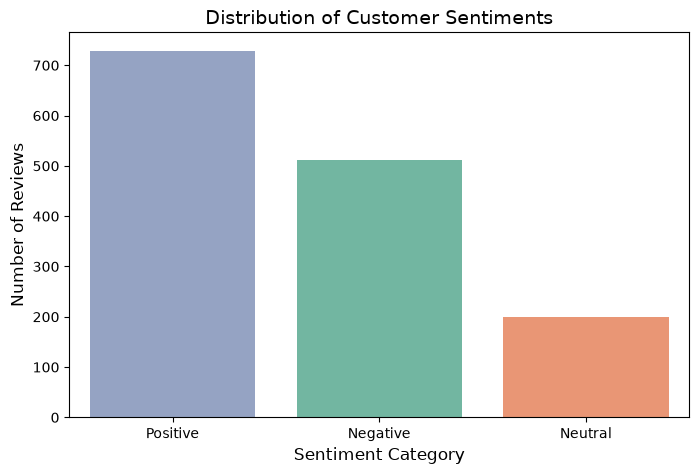

In [13]:
# Visualise the sentiment distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    order=["Positive", "Negative", "Neutral"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Customer Sentiments", fontsize=14)
plt.xlabel("Sentiment Category", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)

plt.show()

### Key Observations

1. Positive sentiment has the highest number of reviews, indicating that most customers gave favourable ratings to the product.
2. Negative sentiment is the second-largest category, showing that a considerable number of customers reported dissatisfaction.
3. Neutral sentiment has the lowest number of reviews, suggesting fewer customers gave moderate ratings.

### EDA Finding

The dataset contains approximately 50.63% positive reviews, 35.56% negative reviews and 13.82% neutral reviews. Although positive reviews form the largest category, the considerable proportion of negative reviews indicates that there is room for product improvement.

In [14]:
# REVIEW LENGTH ANALYSIS

In [15]:
# Calculate the number of words in each review

df["review_length"] = df["cleaned_review"].apply(
    lambda text: len(text.split())
)

# Display review length information

print("REVIEW LENGTH ANALYSIS")
print("=" * 40)

display(df[["cleaned_review", "review_length"]].head(10))


# Statistical summary of review length

print("\nSTATISTICAL SUMMARY OF REVIEW LENGTH")
print("=" * 40)

print(df["review_length"].describe())

REVIEW LENGTH ANALYSIS


,cleaned_review,review_length
0,horrible product very disappointed with the ov...,10
1,camera quality is not like megapixel camera qu...,10
2,overall got the mobile on the launch date batt...,73
3,a big no from me it doesn t work with ghz wifi...,74
4,put your money somewhere else not worth buying...,36
5,too much lagging and slow i will never purchas...,23
6,worst samsung mobile ever this is worst samsun...,38
7,pm,1
8,slow performance the phone hangs a lot and is ...,19
9,don t buy from amazon very poor quality camera...,38



STATISTICAL SUMMARY OF REVIEW LENGTH
count    1440.000000
mean       58.389583
std        40.481453
min         0.000000
25%        34.000000
50%        49.000000
75%        70.000000
max       398.000000
Name: review_length, dtype: float64


In [16]:
# Identify empty and very short reviews

print("EMPTY AND SHORT REVIEW ANALYSIS")
print("=" * 45)


# Count reviews with zero words

empty_reviews = (df["review_length"] == 0).sum()


# Count reviews with three or fewer words

short_reviews = (df["review_length"] <= 3).sum()


print("Empty Reviews:", empty_reviews)

print("Reviews with 3 or fewer words:", short_reviews)


# Display examples of empty reviews

print("\nEMPTY REVIEW EXAMPLES")

display(
    df.loc[
        df["review_length"] == 0,
        ["title", "body", "cleaned_review", "rating"]
    ].head(5)
)


# Display examples of very short reviews

print("\nSHORT REVIEW EXAMPLES")

display(
    df.loc[
        df["review_length"] <= 3,
        ["cleaned_review", "review_length", "rating"]
    ].head(10)
)

EMPTY AND SHORT REVIEW ANALYSIS
Empty Reviews: 2
Reviews with 3 or fewer words: 7

EMPTY REVIEW EXAMPLES


,title,body,cleaned_review,rating
460,असंतोषजनक,इस फोन में कई कमियां है जैसे इसकी नोटिफिकेशन ट...,,1
794,इस फोन में बहुत सारे प्रॉब्लम है,इस फोन में बहुत सारे प्रॉब्लम है चार्ज में लगा...,,1



SHORT REVIEW EXAMPLES


,cleaned_review,review_length,rating
7,pm,1,1
299,prepared good,2,1
460,,0,1
717,m nice phone,3,5
794,,0,1
1106,good like,2,5
1301,very bad,2,1


In [17]:
# FEATURE EXTRACTION USING TF-IDF

In [18]:
# Importing machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [19]:
# Remove reviews that are empty after text cleaning

df_model = df[df["cleaned_review"].str.strip() != ""].copy()

# Define input and output variables

X = df_model["cleaned_review"]

y = df_model["sentiment"]

# Display dataset information

print("Dataset prepared for model building")

print("\nTotal records:", len(df_model))

print("\nInput variable shape:", X.shape)

print("Output variable shape:", y.shape)

print("\nSentiment distribution:")

print(y.value_counts())

Dataset prepared for model building

Total records: 1438

Input variable shape: (1438,)
Output variable shape: (1438,)

Sentiment distribution:
sentiment
Positive    729
Negative    510
Neutral     199
Name: count, dtype: int64


### Handling Non-English Reviews

The text-cleaning process was primarily designed for English-language customer reviews. The regular expression used in preprocessing retains English alphabets and removes other characters.

As a result, reviews written in other languages may lose their original meaning or become empty after cleaning. Such empty reviews are excluded before model training.

This is a limitation of the current project. In future improvements, multilingual language detection and NLP techniques could be implemented to analyse customer reviews written in different languages.

Why 1,438 instead of 1,440?

Two reviews became empty after text cleaning and were excluded from model preparation. Both belonged to the negative category.

In [20]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset split information

print("DATASET SPLITTING RESULTS")
print("=" * 40)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

DATASET SPLITTING RESULTS
Training records: 1150
Testing records: 288

Training sentiment distribution:
sentiment
Positive    583
Negative    408
Neutral     159
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    146
Negative    102
Neutral      40
Name: count, dtype: int64


In [21]:
# Create the TF-IDF vectorizer

from sklearn.feature_extraction.text import TfidfVectorizer

# Create an improved TF-IDF vectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training reviews
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing reviews
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed!
Training data shape: (1150, 5000)
Testing data shape: (288, 5000)


In [22]:
# Display the first 30 extracted features

features = tfidf.get_feature_names_out()

print("First 30 Extracted Features:")

print(features[:30])

First 30 Extracted Features:
['able' 'able to' 'about' 'about it' 'about the' 'about this' 'above'
 'above average' 'absolutely' 'acceptable' 'access' 'according'
 'according to' 'achcha' 'action' 'activities' 'actual' 'actually'
 'adapter' 'adaptive' 'adaptive brightness' 'adaptive refresh' 'add'
 'added' 'additional' 'ads' 'advertised' 'advertising' 'advice'
 'affordable']


In [23]:
# MACHINE LEARNING MODEL BUILDING

In [24]:
# Importing machine learning models

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Importing evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Machine learning models and evaluation metrics imported successfully!")

Machine learning models and evaluation metrics imported successfully!


In [25]:
# Creating the machine learning models

models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "SVM": LinearSVC(
        random_state=42
    )
}

print("Three machine learning models created successfully!")

print("\nModels selected:")
for model_name in models:
    print(model_name)

Three machine learning models created successfully!

Models selected:
Naive Bayes
Logistic Regression
SVM


In [26]:
# Train and evaluate all three machine learning models

results = []

for model_name, model in models.items():

    # Train the model
    model.fit(X_train_tfidf, y_train)

    # Predict sentiment on testing data
    y_pred = model.predict(X_test_tfidf)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Store model performance
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-Score": f1
    })

    print(model_name, "training and evaluation completed.")

# Create a comparison table

results_df = pd.DataFrame(results)

# Sort models by Macro F1-Score

results_df = results_df.sort_values(
    by="Macro F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

Naive Bayes training and evaluation completed.
Logistic Regression training and evaluation completed.
SVM training and evaluation completed.

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,SVM,0.8160,0.7172,0.6644,0.6576
1,Logistic Regression,0.8194,0.8778,0.6425,0.6140
2,Naive Bayes,0.7674,0.5189,0.5804,0.5438


Three machine learning algorithms were evaluated: Multinomial Naive Bayes, Logistic Regression and Support Vector Machine (SVM).

The SVM model achieved the highest Macro F1-score of 65.76%, indicating a better balance between precision and recall across the three sentiment categories.

Logistic Regression achieved an accuracy of 81.94%, while SVM achieved 81.60%. Naive Bayes recorded an accuracy of 76.74%.

Although Logistic Regression had slightly higher accuracy, SVM was selected for further improvement because of its better Macro F1-score and comparatively better performance in identifying Neutral reviews.

In [27]:
# DETAILED MODEL EVALUATION

In [28]:
# Generate classification reports for all models

for model_name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test_tfidf)

    print("\n" + "=" * 60)
    print("CLASSIFICATION REPORT:", model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["Negative", "Neutral", "Positive"],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.81      0.75      0.78       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.75      0.99      0.85       146

    accuracy                           0.77       288
   macro avg       0.52      0.58      0.54       288
weighted avg       0.67      0.77      0.71       288


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.81      0.91      0.86       102
     Neutral       1.00      0.05      0.10        40
    Positive       0.82      0.97      0.89       146

    accuracy                           0.82       288
   macro avg       0.88      0.64      0.61       288
weighted avg       0.84      0.82      0.77       288


CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

    Negative       0.80      0.91      0.85       102
     Neutral       0.

- Naive Bayes: Failed to correctly identify any Neutral reviews.
- Logistic Regression: Correctly identified only 2 out of 40 Neutral reviews.
- SVM: Correctly identified 6 out of 40 Neutral reviews.
  
SVM performs better in terms of macro F1-score because it provides a better overall balance across the three sentiment categories.

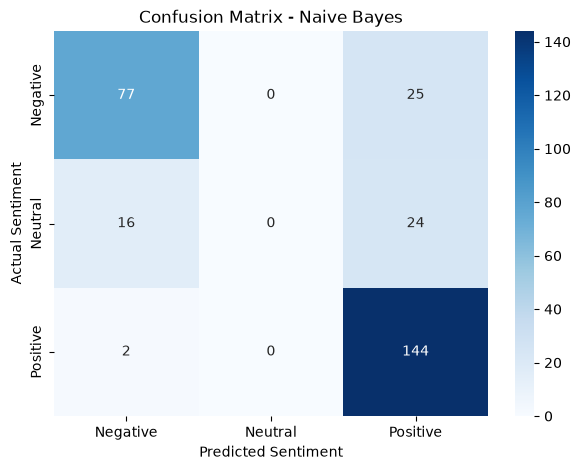

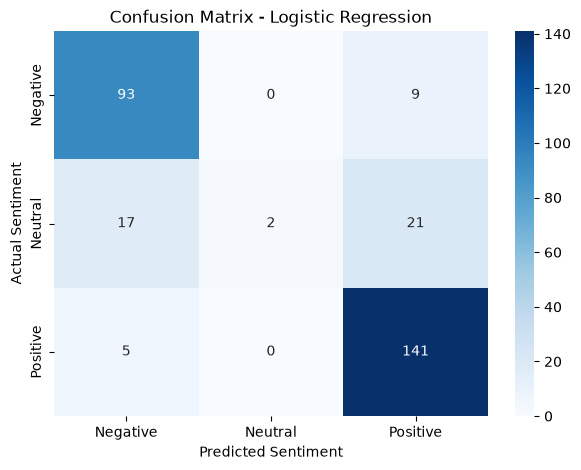

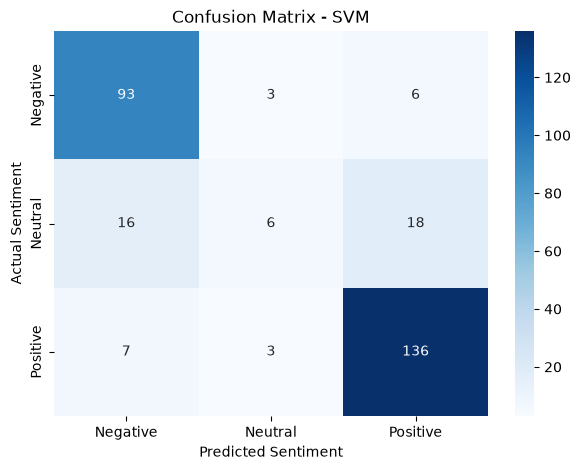

In [29]:
# Generate confusion matrices for all models

for model_name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test_tfidf)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"]
    )

    # Plot confusion matrix
    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Neutral", "Positive"],
        yticklabels=["Negative", "Neutral", "Positive"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")

    plt.show()

### Confusion Matrix Analysis – Original SVM Model

**Negative Reviews:**
- 93 reviews were correctly classified as Negative.
- 3 were incorrectly classified as Neutral.
- 6 were incorrectly classified as Positive.

**Neutral Reviews:**
- 6 reviews were correctly classified as Neutral.
- 16 were incorrectly classified as Negative.
- 18 were incorrectly classified as Positive.

**Positive Reviews:**
- 136 reviews were correctly classified as Positive.
- 7 were incorrectly classified as Negative.
- 3 were incorrectly classified as Neutral.

The diagonal values (93, 6 and 136) represent the correctly classified reviews.

The original SVM model correctly classified 235 out of 288 testing reviews, achieving an accuracy of 81.60%.

### Model Selection – Support Vector Machine (SVM)

After evaluating Multinomial Naive Bayes, Logistic Regression and Support Vector Machine (SVM), the SVM model was selected for further improvement.

Logistic Regression achieved the highest accuracy of 81.94%, while SVM achieved an accuracy of 81.60%. However, SVM recorded the highest Macro F1-score of 65.76%, compared to 61.40% for Logistic Regression and 54.38% for Naive Bayes.

SVM also performed better in identifying Neutral reviews, achieving an F1-score of 0.23 compared to 0.10 for Logistic Regression and 0.00 for Naive Bayes.

Since the dataset contains three sentiment categories with different numbers of reviews, Macro F1-score was considered an important evaluation metric because it gives equal importance to all three classes.

Therefore, SVM was selected for further improvement based on its comparatively better balance across the three sentiment categories.

In [30]:
# Importing Joblib to save the trained machine learning model

import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [31]:
from sklearn.svm import LinearSVC

# Create an SVM model with balanced class weights

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

print("Improved SVM model trained successfully!")

Improved SVM model trained successfully!


In [33]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Predict testing reviews
y_pred = svm_model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate Macro F1-score
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("IMPROVED SVM MODEL PERFORMANCE")
print("=" * 40)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Macro F1-score:", round(macro_f1 * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

IMPROVED SVM MODEL PERFORMANCE
Accuracy: 81.94 %
Macro F1-score: 69.23 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.89      0.85       102
     Neutral       0.50      0.25      0.33        40
    Positive       0.87      0.92      0.90       146

    accuracy                           0.82       288
   macro avg       0.73      0.69      0.69       288
weighted avg       0.80      0.82      0.80       288



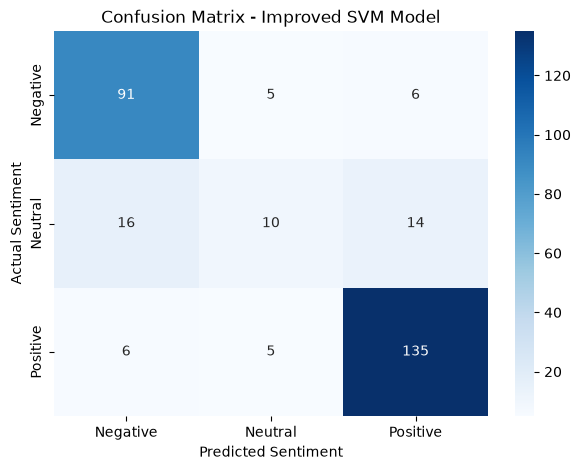

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("Confusion Matrix - Improved SVM Model")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [35]:
import joblib

# Save the improved SVM model
joblib.dump(svm_model, "svm_sentiment_model.pkl")

# Save the corresponding TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Improved SVM model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Improved SVM model saved successfully!
TF-IDF vectorizer saved successfully!


In [32]:
# Verify that the model files have been saved

import os

print("Checking saved model files:")

print("SVM Model:", os.path.exists("svm_sentiment_model.pkl"))

print("TF-IDF Vectorizer:", os.path.exists("tfidf_vectorizer.pkl"))

Checking saved model files:
SVM Model: True
TF-IDF Vectorizer: True


In [31]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os

print("Current folder:", os.getcwd())

print("App file exists:", os.path.exists("app.py"))

Current folder: C:\Users\adish\python_practice\Projects
App file exists: True


In [36]:
joblib.dump(svm_model, "svm_sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

# Conclusion

The project successfully developed an NLP-based customer review sentiment analysis system using Samsung mobile phone customer reviews.

Three machine learning algorithms were evaluated: Multinomial Naive Bayes, Logistic Regression and Support Vector Machine (SVM). Based on the Macro F1-score, SVM was selected for further improvement.

The SVM model was improved by implementing balanced class weights to address the unequal distribution of sentiment categories.

The improved model achieved an accuracy of 81.94% and a Macro F1-score of 69.23%.

The Neutral sentiment F1-score increased from 0.23 to 0.33, indicating better identification of Neutral customer reviews.

The results demonstrate that class balancing helped improve the model's overall performance. However, Neutral sentiment classification remains a challenge, as some Neutral reviews are still incorrectly classified as Positive or Negative.

The trained SVM model and TF-IDF vectorizer were saved and integrated into a Streamlit application, allowing users to analyse individual customer reviews and upload CSV files containing multiple reviews.

Overall, the project demonstrates how Natural Language Processing and Machine Learning can be used to extract meaningful sentiment insights from customer feedback.